# 🚀 Practice Day 47

**📅 Date:** **2026-10-30**  
**📁 Category:** **Phase 2 · Pandas 심화(GroupBy&Pivot) (Round 4/5)**

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice groupby aggregation and pivot_table cross-tabulation across two dimensions — bank branch and financial product type
  (groupby 집계와 pivot_table 교차분석을 지점·금융상품유형 두 차원에 걸쳐 연습하기)
- Find which branch and which product type drive the most revenue, and where they intersect
  (매출을 가장 많이 견인하는 지점과 상품유형, 그리고 그 둘이 만나는 지점 찾기)

---
# 📂 Dataset

**Dataset Name:** Meridian Trust Bank — Monthly Performance by Branch & Product Type / Meridian Trust Bank — 지점별·상품유형별 월간 실적 데이터

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 6 months (Jan-Jun 2024) of monthly new-contract counts and revenue for a 6-branch bank (Midtown, SoHo, Chelsea, Williamsburg, Astoria, Forest Hills), broken down by 4 product types (Savings, Loans, Credit Cards, Insurance). Revenue is in USD. 144 rows total (6 branches × 4 product types × 6 months), clean — no missing values or duplicates. The focus is building single-dimension groupby summaries and a branch × product-type pivot table.
(은행 지점 6곳(Midtown/SoHo/Chelsea/Williamsburg/Astoria/Forest Hills)에서 6개월(2024년 1~6월) 동안 4개 금융상품유형(Savings/Loans/Credit Cards/Insurance)별로 집계된 월간 신규계약건수와 실적금액 데이터입니다. 실적금액은 USD입니다. 총 144행(6지점×4상품유형×6개월), 결측치·중복 없이 깨끗합니다. groupby로 지점별·상품유형별 집계를, pivot_table로 지점×상품유형 교차표를 만드는 데 초점을 둡니다.)

## Dataset Preview

In [56]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate monthly performance for a 6-branch bank, by financial product type ---
branches = ['Midtown', 'Chelsea', 'Williamsburg', 'Astoria', 'SoHo', 'Forest Hills']
branch_mult = {'Midtown': 1.35, 'Chelsea': 1.1, 'Williamsburg': 0.95, 'Astoria': 0.8,
               'SoHo': 1.2, 'Forest Hills': 0.7}

product_types = ['Savings', 'Loans', 'Credit Cards', 'Insurance']
base_contracts = {'Savings': 85, 'Loans': 18, 'Credit Cards': 48, 'Insurance': 22}
avg_value = {'Savings': 1_200, 'Loans': 42_000, 'Credit Cards': 2_800, 'Insurance': 3_500}  # USD

months = pd.date_range('2024-01-01', periods=6, freq='MS')

rows = []
for b in branches:
    for pt in product_types:
        for i, m in enumerate(months):
            noise = rng.normal(1.0, 0.11)
            contracts = base_contracts[pt] * branch_mult[b] * noise
            contracts = max(1, int(round(contracts)))
            value_noise = rng.normal(1.0, 0.05)
            revenue = int(round(contracts * avg_value[pt] * value_noise))  # nearest USD
            rows.append({'month': m, 'branch': b, 'product_type': pt, 'contracts': contracts, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['month', 'branch', 'product_type']).reset_index(drop=True)

df.head(10)


,month,branch,product_type,contracts,revenue
0,2024-01-01,Astoria,Credit Cards,38,106183
1,2024-01-01,Astoria,Insurance,20,70768
2,2024-01-01,Astoria,Loans,15,660956
3,2024-01-01,Astoria,Savings,62,72855
4,2024-01-01,Chelsea,Credit Cards,47,134871
5,2024-01-01,Chelsea,Insurance,21,75290
6,2024-01-01,Chelsea,Loans,16,660748
7,2024-01-01,Chelsea,Savings,100,120405
8,2024-01-01,Forest Hills,Credit Cards,35,102962
9,2024-01-01,Forest Hills,Insurance,14,46275


## Dataset Information

In [57]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   month         144 non-null    datetime64[us]
 1   branch        144 non-null    str           
 2   product_type  144 non-null    str           
 3   contracts     144 non-null    int64         
 4   revenue       144 non-null    int64         
dtypes: datetime64[us](1), int64(2), str(2)
memory usage: 5.8 KB

Shape: (144, 5)


,month,branch,product_type,contracts,revenue
count,144,144,144,144.000000,1.440000e+02
unique,NaN,6,4,NaN,NaN
top,NaN,Astoria,Credit Cards,NaN,NaN
freq,NaN,24,36,NaN,NaN
mean,2024-03-16 20:00:00,NaN,NaN,43.708333,2.715964e+05
min,2024-01-01 00:00:00,NaN,NaN,12.000000,4.627500e+04
25%,2024-02-01 00:00:00,NaN,NaN,20.000000,8.439950e+04
50%,2024-03-16 12:00:00,NaN,NaN,32.500000,1.159165e+05
75%,2024-05-01 00:00:00,NaN,NaN,62.000000,2.873212e+05
max,2024-06-01 00:00:00,NaN,NaN,126.000000,1.166914e+06


---
# ❓ Business Questions

1. **(Analysis)** Which branch generated the highest total revenue, and which the lowest?
   (총매출 기준 최고·최저 지점은?)
2. **(Analysis)** Which product type generated the highest total revenue overall, and which the lowest?
   (전체 상품유형 중 최고·최저 매출 유형은?)
3. **(Analysis)** When you cross-tabulate branch and product type, which single combination generated the most revenue — and which the least?
   (지점×상품유형으로 교차분석했을 때, 가장 매출이 높은 조합과 가장 낮은 조합은?)
4. **(Visualization)** How do the six branches compare on total revenue?
   (6개 지점의 총매출을 비교하면?)
5. **(Visualization)** How does revenue break down across the branch × product-type grid all at once?
   (지점×상품유형 조합별 매출은 한눈에 어떻게 보이는가?)

---
# 🔍 Data Cleaning Check


In [58]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
month           0
branch          0
product_type    0
contracts       0
revenue         0
dtype: int64

Duplicate rows: 0

Dtypes
month           datetime64[us]
branch                     str
product_type               str
contracts                int64
revenue                  int64
dtype: object

Column names
['month', 'branch', 'product_type', 'contracts', 'revenue']

Text columns — unique counts
branch          6
product_type    4
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which branch generated the highest total revenue, and which the lowest? (총매출 기준 최고·최저 지점은?)

**Result:** Midtown has the highest revenue at **$8,980,760**. Forest Hills has the lowest at **$4,501,594**. The gap is **$4,479,166**.  
(매출 1위는 Midtown $8,980,760, 맨 아래는 Forest Hills $4,501,594. 차이는 $4,479,166)

**Insight:** SoHo is next at **$7,367,631**, which is **$1,613,129** below Midtown. Chelsea is **$6,827,539**, Williamsburg **$6,149,013**, and Astoria **$5,283,346**.  
(다음은 SoHo $7,367,631로 Midtown보다 $1,613,129 적음. Chelsea $6,827,539, Williamsburg $6,149,013, Astoria $5,283,346)

In [59]:
# Question 1: total revenue by branch
revenue_by_branch = df.groupby('branch')['revenue'].sum().sort_values(ascending=False)

revenue_by_branch

branch
Midtown         8980760
SoHo            7367631
Chelsea         6827539
Williamsburg    6149013
Astoria         5283346
Forest Hills    4501594
Name: revenue, dtype: int64

## Question 2

**Question:** Which product type generated the highest total revenue overall, and which the lowest? (최고·최저 매출 상품유형은?)

**Result:** Loans are highest at **$27,634,902**. Insurance is lowest at **$2,758,749**. The gap is **$24,876,153**.  
(1위는 Loans $27,634,902, 맨 아래는 Insurance $2,758,749. 차이는 $24,876,153)

**Insight:** Loans are **70.7%** of the **$39,109,883** total. Credit Cards are **$5,058,102** and Savings are **$3,658,130**.  
(Loans는 전체 $39,109,883의 70.7%. Credit Cards $5,058,102, Savings $3,658,130)

In [60]:
# Question 2: total revenue by product_type
revenue_by_product_type = df.groupby('product_type')['revenue'].sum().sort_values(ascending=False)

revenue_by_product_type

product_type
Loans           27634902
Credit Cards     5058102
Savings          3658130
Insurance        2758749
Name: revenue, dtype: int64

## Question 3

**Question:** When you cross-tabulate branch and product type, which single combination generated the most revenue — and which the least? (지점×상품유형 교차분석에서 최고·최저 조합은?)

**Result:** The highest cell is Midtown · Loans at **$6,381,319**. The lowest is Forest Hills · Insurance at **$322,516**. The gap is **$6,058,803**.  
(최고는 Midtown · Loans $6,381,319. 최저는 Forest Hills · Insurance $322,516. 차이는 $6,058,803)

**Insight:** Midtown · Loans is **71.1%** of Midtown's **$8,980,760**. The lowest cell is still a recorded product total, not a missing value.  
(Midtown · Loans는 Midtown $8,980,760의 71.1%. 최저 칸도 결측이 아니라 집계된 상품 매출)

In [61]:
# Question 3: branch x product_type cross-tab
pivot = (
    df.pivot_table(
        index='branch',
        columns='product_type',
        values='revenue',
        aggfunc='sum',
    )
    .reindex(
        index=revenue_by_branch.index,
        columns=revenue_by_product_type.index,
    )
)
display(pivot)

stacked = pivot.stack()

display(stacked)

print(stacked.idxmax(), stacked.max())
print(stacked.idxmin(), stacked.min())

product_type,Loans,Credit Cards,Savings,Insurance
branch,,,,
Midtown,6381319,1149178,818334,631929
SoHo,5096041,1042108,742712,486770
Chelsea,4810612,875753,660214,480960
Williamsburg,4399348,762496,540809,446360
Astoria,3791868,631980,469284,390214
Forest Hills,3155714,596587,426777,322516


branch        product_type
Midtown       Loans           6381319
              Credit Cards    1149178
              Savings          818334
              Insurance        631929
SoHo          Loans           5096041
              Credit Cards    1042108
              Savings          742712
              Insurance        486770
Chelsea       Loans           4810612
              Credit Cards     875753
              Savings          660214
              Insurance        480960
Williamsburg  Loans           4399348
              Credit Cards     762496
              Savings          540809
              Insurance        446360
Astoria       Loans           3791868
              Credit Cards     631980
              Savings          469284
              Insurance        390214
Forest Hills  Loans           3155714
              Credit Cards     596587
              Savings          426777
              Insurance        322516
dtype: int64

('Midtown', 'Loans') 6381319
('Forest Hills', 'Insurance') 322516


---
# 📈 Visualization

**Chart 1:** Bar chart — total revenue by branch (막대그래프: 지점별 총매출)

*Interpretation:* The bars follow the branch table: Midtown **$8,980,760**, SoHo **$7,367,631**, Chelsea **$6,827,539**, Williamsburg **$6,149,013**, Astoria **$5,283,346**, Forest Hills **$4,501,594**.  
(막대 순서는 지점 표와 같음. Midtown $8,980,760, SoHo $7,367,631, Chelsea $6,827,539, Williamsburg $6,149,013, Astoria $5,283,346, Forest Hills $4,501,594)

---

**Chart 2:** Heatmap — revenue by branch × product type (히트맵: 지점×상품유형별 매출)

*Interpretation:* The darkest cell is the top-left, Midtown · Loans at **$6,381,319**. The lightest is the bottom-right, Forest Hills · Insurance at **$322,516**.  
(가장 어두운 칸은 왼쪽 위 Midtown · Loans $6,381,319. 가장 밝은 칸은 오른쪽 아래 Forest Hills · Insurance $322,516)

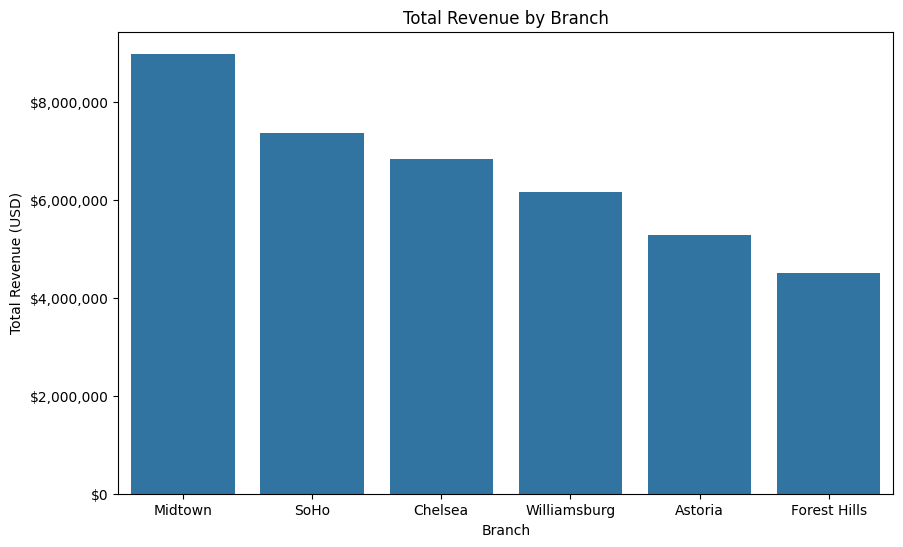

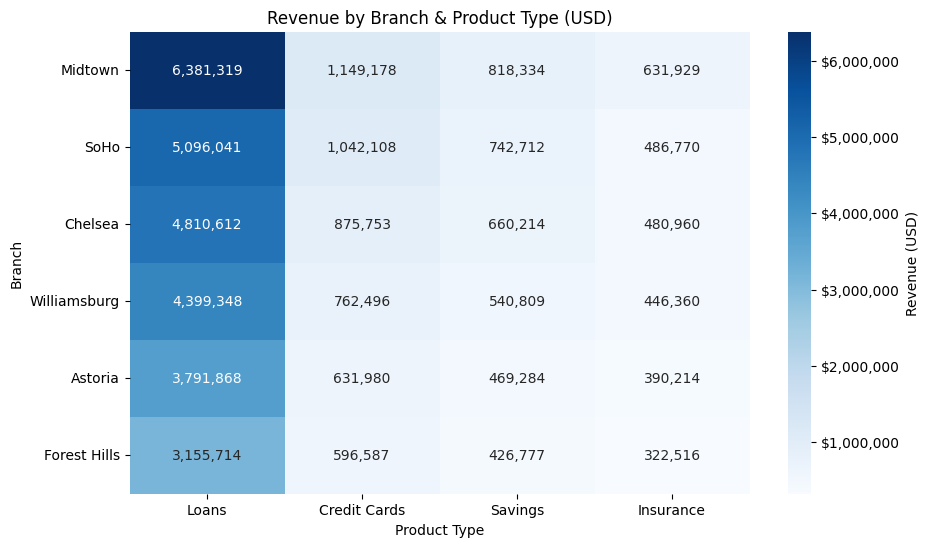

In [62]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: total revenue by branch (bar)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=revenue_by_branch.index, y=revenue_by_branch.values, ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Total Revenue by Branch')
ax.set_xlabel('Branch')
ax.set_ylabel('Total Revenue (USD)')
plt.show()

# Chart 2: branch x product_type revenue (heatmap)
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='Blues', cbar_kws={'label': 'Revenue (USD)'}, ax=ax)
ax.collections[0].colorbar.ax.yaxis.set_major_formatter('${x:,.0f}')
ax.collections[0].colorbar.ax.yaxis.get_offset_text().set_visible(False)
ax.set_title('Revenue by Branch & Product Type (USD)')
ax.set_xlabel('Product Type')
ax.set_ylabel('Branch')
ax.tick_params(axis='y', rotation=0)

---
# 💼 Business Insights
*What did I discover?*

- Midtown leads the six branches at **$8,980,760**. Forest Hills is last at **$4,501,594**.  
  (여섯 지점 중 Midtown이 $8,980,760으로 1위. Forest Hills는 $4,501,594로 맨 아래)
- Loans are **$27,634,902**, **70.7%** of all revenue. Insurance is **$2,758,749**.  
  (Loans는 $27,634,902로 전체의 70.7%. Insurance는 $2,758,749)
- The single largest cell is Midtown · Loans at **$6,381,319**. The smallest is Forest Hills · Insurance at **$322,516**.  
  (칸 하나로는 Midtown · Loans $6,381,319가 가장 크고, Forest Hills · Insurance $322,516이 가장 작음)  

---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Treat Loans as the main product. It is **$24,876,153** above Insurance.  
   (Loans를 핵심 상품으로 둘 것. Insurance보다 $24,876,153 많음)
2. Read a branch total together with its Loans cell. Midtown's **$8,980,760** includes Midtown · Loans at **$6,381,319**.  
   (지점 합계는 그 지점의 Loans 칸과 같이 볼 것. Midtown $8,980,760 안에 Midtown · Loans $6,381,319가 있음)
3. Do not rank Forest Hills by the **$322,516** Insurance cell alone. Its branch total is **$4,501,594**.  
   (Forest Hills를 Insurance 칸 $322,516만으로 순위를 매기지 않기. 지점 합계는 $4,501,594)  

---
# ❌ Mistakes
*What mistakes did I make today?*

- The heatmap x-axis said Room Type. These columns are product types.  
  (히트맵 x축이 Room Type으로 적혀 있었음. 이 열은 상품 유형)
- The color bar showed `1e6` instead of full dollar amounts.  
  (색 막대가 금액 전체가 아니라 `1e6`으로 표시됐음)  

---
# ✅ What I Learned
*Today's biggest lesson*

- `groupby` plus `sum` answers one dimension: branch, or product type.  
  (`groupby`와 `sum`은 지점 하나, 또는 상품 유형 하나를 집계함)
- `pivot_table(..., aggfunc='sum')` is the branch × product grid. `stack()` turns each cell into one row, so `idxmax()` and `idxmin()` can name the pair.  
  (`pivot_table(..., aggfunc='sum')`이 지점×상품 표. `stack()`은 칸을 행으로 만들고, `idxmax()`와 `idxmin()`이 그 쌍의 이름을 줌)
- Reindex the heatmap with the branch order and the product order, and format the color bar in dollars instead of `1e6`.  
  (히트맵은 지점 순서와 상품 순서로 다시 맞추고, 색 막대는 `1e6`이 아니라 달러로 표시)  

---
# 🧠 Reflection

**What was difficult?**  
Seeing which cell `idxmax()` was pointing at in the wide table.  
(넓은 표에서 `idxmax()`가 어느 칸을 가리키는지 보는 것)

**Why?**  
`pivot_table` keeps branches as rows and products as columns. The max is one cell, not a whole row.  
(`pivot_table`은 지점을 행으로, 상품을 열로 둠. 최댓값은 행 전체가 아니라 칸 하나)

**How did I solve it?**  
Used `stack()` so each branch-product pair was one row, then printed `idxmax()` with `max()` and `idxmin()` with `min()`.  
(`stack()`으로 지점·상품 쌍을 한 행으로 만든 뒤, `idxmax()`와 `max()`, `idxmin()`과 `min()`을 같이 출력)

**What would I do differently next time?**  
Check the heatmap axis title and turn off `1e6` before reading the colors.  
(색을 읽기 전에 히트맵 축 제목을 보고 `1e6`을 끌 것)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
The branch ranking, the Loans share of **70.7%**, and the Midtown · Loans cell are clear. A heatmap still needs a check that the axis name and the color bar match the dollars.  
(지점 순위, Loans 비중 70.7%, Midtown · Loans 칸은 이해함. 히트맵은 축 이름과 색 막대가 달러와 맞는지 확인이 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The two groupby tables were direct. The hard part was turning the grid into one winning pair.  
(groupby 두 표는 바로 보였음. 어려운 부분은 표를 1위 쌍 하나로 만드는 것이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 48 — SQL basics with DuckDB (Round 4/5)  
  (DuckDB로 SELECT, GROUP BY, 집계)  